In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder




In [12]:
df=pd.read_csv("C:/Users/hp/OneDrive/Documents/AI Project/train.csv")
df.head()


,Timestamp,Signal Strength (dBm),SNR,Call Duration (s),Environment,Attenuation,Distance to Tower (km),Tower ID,User ID,Call Type,Incoming/Outgoing
0,2022-01-03 17:46:13,-84.119763,25.940082,1713.800550,urban,14.690438,2.243176,5,25,data,incoming
1,2022-01-04 17:29:31,-87.806131,15.937354,345.371848,home,6.213698,5.002566,3,22,voice,incoming
2,2022-01-05 17:14:01,-116.575176,14.709384,259.285043,open,4.494415,8.705974,2,5,voice,incoming
3,2022-01-06 16:02:29,-82.961183,21.727165,357.974004,home,7.619957,7.427025,5,33,data,outgoing
4,2022-01-07 22:19:17,-85.012574,26.058158,398.006716,urban,10.655159,0.612071,5,8,voice,outgoing


In [13]:
df.columns.to_list()

['Timestamp',
 'Signal Strength (dBm)',
 'SNR',
 'Call Duration (s)',
 'Environment',
 'Attenuation',
 'Distance to Tower (km)',
 'Tower ID',
 'User ID',
 'Call Type',
 'Incoming/Outgoing']

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               463 non-null    str    
 1   Signal Strength (dBm)   463 non-null    float64
 2   SNR                     463 non-null    float64
 3   Call Duration (s)       463 non-null    float64
 4   Environment             463 non-null    str    
 5   Attenuation             463 non-null    float64
 6   Distance to Tower (km)  463 non-null    float64
 7   Tower ID                463 non-null    int64  
 8   User ID                 463 non-null    int64  
 9   Call Type               463 non-null    str    
 10  Incoming/Outgoing       463 non-null    str    
dtypes: float64(5), int64(2), str(4)
memory usage: 56.5 KB


In [15]:
df.isnull().sum()

Timestamp                 0
Signal Strength (dBm)     0
SNR                       0
Call Duration (s)         0
Environment               0
Attenuation               0
Distance to Tower (km)    0
Tower ID                  0
User ID                   0
Call Type                 0
Incoming/Outgoing         0
dtype: int64

In [16]:
# Cell 3: Inspect the dataset

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (463, 11)

Column names:
['Timestamp', 'Signal Strength (dBm)', 'SNR', 'Call Duration (s)', 'Environment', 'Attenuation', 'Distance to Tower (km)', 'Tower ID', 'User ID', 'Call Type', 'Incoming/Outgoing']

First five rows:


,Timestamp,Signal Strength (dBm),SNR,Call Duration (s),Environment,Attenuation,Distance to Tower (km),Tower ID,User ID,Call Type,Incoming/Outgoing
0,2022-01-03 17:46:13,-84.119763,25.940082,1713.800550,urban,14.690438,2.243176,5,25,data,incoming
1,2022-01-04 17:29:31,-87.806131,15.937354,345.371848,home,6.213698,5.002566,3,22,voice,incoming
2,2022-01-05 17:14:01,-116.575176,14.709384,259.285043,open,4.494415,8.705974,2,5,voice,incoming
3,2022-01-06 16:02:29,-82.961183,21.727165,357.974004,home,7.619957,7.427025,5,33,data,outgoing
4,2022-01-07 22:19:17,-85.012574,26.058158,398.006716,urban,10.655159,0.612071,5,8,voice,outgoing



Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               463 non-null    str    
 1   Signal Strength (dBm)   463 non-null    float64
 2   SNR                     463 non-null    float64
 3   Call Duration (s)       463 non-null    float64
 4   Environment             463 non-null    str    
 5   Attenuation             463 non-null    float64
 6   Distance to Tower (km)  463 non-null    float64
 7   Tower ID                463 non-null    int64  
 8   User ID                 463 non-null    int64  
 9   Call Type               463 non-null    str    
 10  Incoming/Outgoing       463 non-null    str    
dtypes: float64(5), int64(2), str(4)
memory usage: 56.5 KB

Summary of numeric columns:


,Signal Strength (dBm),SNR,Call Duration (s),Attenuation,Distance to Tower (km),Tower ID,User ID
count,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000
mean,-84.957137,19.834262,895.324971,5.459605,5.064669,5.531317,52.198704
std,14.349536,5.579039,529.838188,3.502259,2.956370,2.837327,27.969438
min,-118.681318,10.271411,11.520904,0.042255,0.026375,1.000000,1.000000
25%,-95.936519,14.857527,418.499303,2.815069,2.509455,3.000000,29.000000
50%,-84.230276,19.584328,910.509884,4.758147,5.183831,6.000000,54.000000
75%,-74.430044,24.648712,1362.754612,7.573055,7.708894,8.000000,75.500000
max,-50.122222,29.963213,1795.175137,14.939793,9.981806,10.000000,100.000000


Numeric columns: ['Signal Strength (dBm)', 'SNR', 'Call Duration (s)', 'Attenuation', 'Distance to Tower (km)', 'Tower ID', 'User ID']


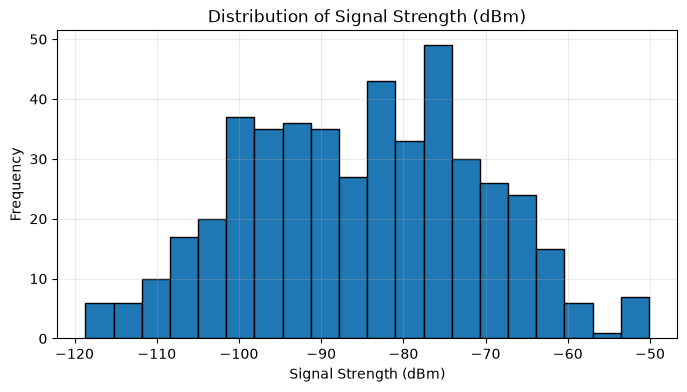

In [17]:

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_columns)

# Plotting distribution of the first continuous feature
column_to_plot = "Signal Strength (dBm)"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot].dropna(), bins=20, edgecolor="black")
plt.title(f"Distribution of {column_to_plot}")
plt.xlabel(column_to_plot)
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()



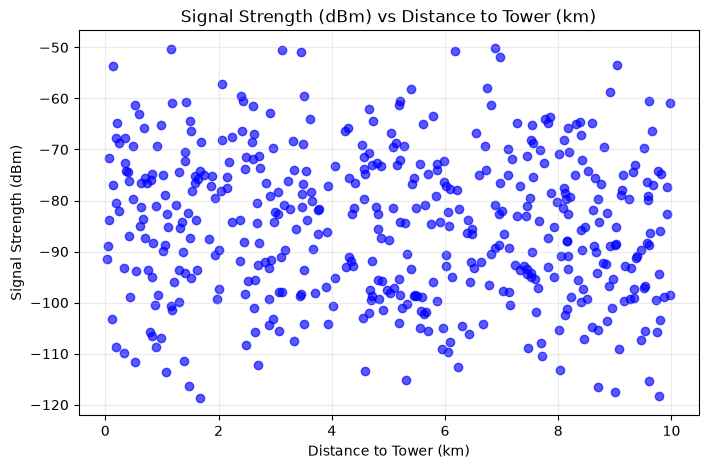

In [18]:
feature_for_plot = "Distance to Tower (km)"
target_for_plot = "Signal Strength (dBm)"

plt.figure(figsize=(8, 5))
plt.scatter(df[feature_for_plot], df[target_for_plot], alpha=0.65, color="blue")
plt.title(f"{target_for_plot} vs {feature_for_plot}")
plt.xlabel(feature_for_plot)
plt.ylabel(target_for_plot)
plt.grid(alpha=0.25)
plt.show()


In [19]:
df = df.drop_duplicates().copy()

# Target for regression (e.g., predicting Signal Strength)
target_column = "Signal Strength (dBm)"

# Select feature columns (excluding Timestamp, ID columns, and target)
feature_columns = [
    "SNR",
    "Call Duration (s)",
    "Environment",
    "Attenuation",
    "Distance to Tower (km)",
    "Call Type",
    "Incoming/Outgoing"
]

print("Target Column:", target_column)
print("Feature Columns:", feature_columns)
display(df[[target_column] + feature_columns].head())

Target Column: Signal Strength (dBm)
Feature Columns: ['SNR', 'Call Duration (s)', 'Environment', 'Attenuation', 'Distance to Tower (km)', 'Call Type', 'Incoming/Outgoing']


,Signal Strength (dBm),SNR,Call Duration (s),Environment,Attenuation,Distance to Tower (km),Call Type,Incoming/Outgoing
0,-84.119763,25.940082,1713.800550,urban,14.690438,2.243176,data,incoming
1,-87.806131,15.937354,345.371848,home,6.213698,5.002566,voice,incoming
2,-116.575176,14.709384,259.285043,open,4.494415,8.705974,voice,incoming
3,-82.961183,21.727165,357.974004,home,7.619957,7.427025,data,outgoing
4,-85.012574,26.058158,398.006716,urban,10.655159,0.612071,voice,outgoing


In [20]:
# Separate features (X) and target (y)
X = df[feature_columns].copy()
y = df[target_column].copy()

# Identify numerical and categorical column groups
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Define numerical and categorical transformers
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessors
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Input shape (X):", X.shape)
print("Target shape (y):", y.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Rows available for modeling:", len(df))

Input shape (X): (463, 7)
Target shape (y): (463,)
Numeric features: ['SNR', 'Call Duration (s)', 'Attenuation', 'Distance to Tower (km)']
Categorical features: ['Environment', 'Call Type', 'Incoming/Outgoing']
Rows available for modeling: 463


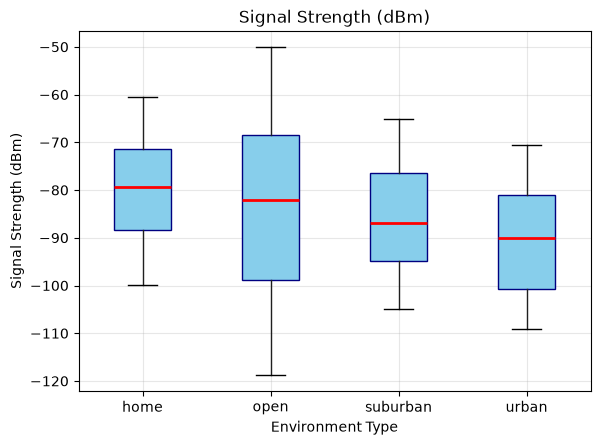

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load your dataset first
df = pd.read_csv("train.csv")  # Replace "train.csv" with your actual file path if different

# 2. Plot the boxplot
df.boxplot(
    column='Signal Strength (dBm)', 
    by='Environment', 
    patch_artist=True,
    boxprops=dict(facecolor='skyblue', color='navy'),
    medianprops=dict(color='red', linewidth=2)
)

plt.suptitle('')  # Removes default pandas title
plt.xlabel('Environment Type')
plt.ylabel('Signal Strength (dBm)')
plt.grid(alpha=0.3)
plt.show()

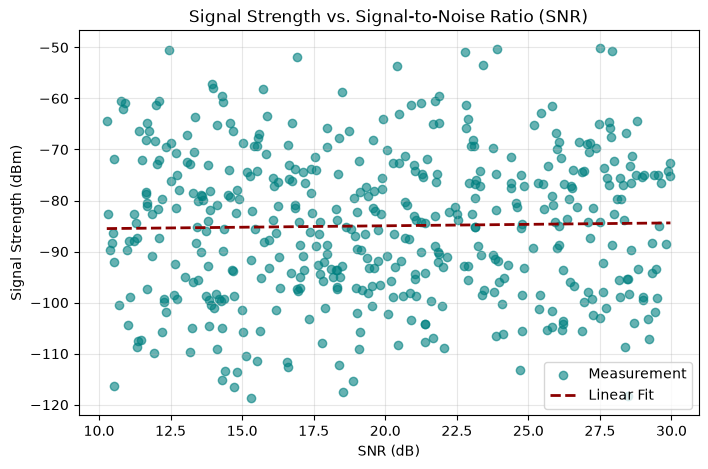

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df['SNR'], df['Signal Strength (dBm)'], alpha=0.6, color='teal', label='Measurement')

# Linear Trendline Calculation
z = np.polyfit(df['SNR'], df['Signal Strength (dBm)'], 1)
p = np.poly1d(z)
plt.plot(df['SNR'].sort_values(), p(df['SNR'].sort_values()), color='darkred', linestyle='--', linewidth=2, label='Linear Fit')

plt.title('Signal Strength vs. Signal-to-Noise Ratio (SNR)')
plt.xlabel('SNR (dB)')
plt.ylabel('Signal Strength (dBm)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

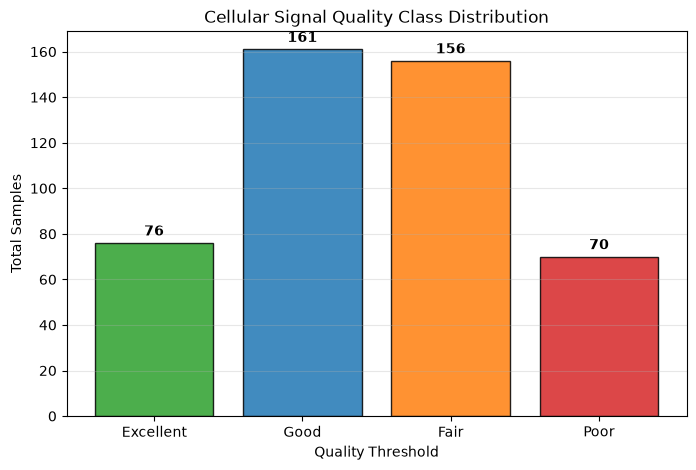

In [24]:
import matplotlib.pyplot as plt

# Helper function to assign standard RF quality bands
def categorize_signal(dbm):
    if  dbm >= -70:
        return 'Excellent (>= -70 dBm)'
    elif dbm >= -85:
        return 'Good (-70 to -85 dBm)'
    elif dbm >= -100:
        return 'Fair (-85 to -100 dBm)'
    else:
        return 'Poor (< -100 dBm)'

df['Quality_Band'] = df['Signal Strength (dBm)'].apply(categorize_signal)
counts = df['Quality_Band'].value_counts().reindex([
    'Excellent (>= -70 dBm)', 'Good (-70 to -85 dBm)', 'Fair (-85 to -100 dBm)', 'Poor (< -100 dBm)'
]).fillna(0)

colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

plt.figure(figsize=(8, 5))
bars = plt.bar(['Excellent', 'Good', 'Fair', 'Poor'], counts.values, color=colors, edgecolor='black', alpha=0.85)

# Annotate counts on top of bars
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{int(height)}',
 xy=(bar.get_x() + bar.get_width() / 2, height),
xytext=(0, 3),
textcoords="offset points",
 ha='center', va='bottom', fontweight='bold')

plt.title('Cellular Signal Quality Class Distribution')
plt.xlabel('Quality Threshold')
plt.ylabel('Total Samples')
plt.grid(axis='y', alpha=0.3)
plt.show()